# Analiza zachowań użytkowników sklepu internetowego

**Retailrocket — I etap projektu, analiza w Pythonie**

*Mateusz Konieczny, 257328*

Chcę sprawdzić, jak użytkownicy przeglądają sklep, jak często kupują i czym różnią się kupujący od pozostałych osób. Na końcu przygotuję tabele do dalszej pracy w Power BI - to będzie zwięczenie I etapu. Etap kolejny to przygotowanie dashbourdu w Power BI.

## 1. Wczytanie bibliotek

In [75]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

Dokonoamy wstepnej analizy ekploracyjnej. Zaczniemy od wczytania danych i przyjrzenia się czym dokładnie są nasze kolumny.

## 2. Wczytanie danych

In [76]:
df = pd.read_csv('input_data/events.csv', dtype={'transactionid': 'Int64'})
# Używamy dtype={'transactionid': 'Int64'},
# ponieważ jeżeli pandas zobaczyłby puste wartości uznałby całą kolumnę za float64
print('Wiersze i kolumny:', df.shape)
df.head()

Wiersze i kolumny: (2756101, 5)


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,<NA>
1,1433224214164,992329,view,248676,<NA>
2,1433221999827,111016,view,318965,<NA>
3,1433221955914,483717,view,253185,<NA>
4,1433221337106,951259,view,367447,<NA>


| Kolumna | Znaczenie |
|---|---|
| `timestamp` | Unix timestamp w milisekundach |
| `visitorid` | Identyfikator użytkownika widoczny w logu |
| `event` | Rodzaj zdarzenia — view, addtocart lub transaction |
| `itemid` | Identyfikator produktu |
| `transactionid` | Identyfikator transakcji, wypełniony przy zakupie |

Użytkownik może wykonać wiele zdarzeń. Jedna transakcja może obejmować kilka produktów i występować w kilku wierszach.

## 3. Kontrola jakości danych

Sprawdzamy typy kolumn, braki i czy występują identyczne wiersze.

In [77]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype
---  ------         -----
 0   timestamp      int64
 1   visitorid      int64
 2   event          str  
 3   itemid         int64
 4   transactionid  Int64
dtypes: Int64(1), int64(3), str(1)
memory usage: 107.8 MB


In [78]:
liczba_duplikatow = df.duplicated().sum()
print('Nadmiarowe identyczne wiersze:', liczba_duplikatow)
print('Udział duplikatów:', round(liczba_duplikatow / len(df) * 100, 4), '%')

Nadmiarowe identyczne wiersze: 460
Udział duplikatów: 0.0167 %


In [79]:
kontrola = pd.DataFrame({
    'typ': df.dtypes.astype(str),
    'braki': df.isna().sum(),
    'braki_proc': df.isna().mean() * 100
})
kontrola.round(2)

,typ,braki,braki_proc
timestamp,int64,0,0.00
visitorid,int64,0,0.00
event,str,0,0.00
itemid,int64,0,0.00
transactionid,Int64,2733644,99.19


Sprawdzimy czy braki w `transactionid` występują tylko dla klas `view` oraz `addtocart`, jeśli nie to musielibyśmy się tym zająć - `transactionid` powinno być podane tylko przy transakcji.

In [80]:
pd.crosstab(df['event'], df['transactionid'].notna()).rename(
    columns={False: 'Brak ID transakcji', True: 'ID transakcji obecne'}
)

transactionid,Brak ID transakcji,ID transakcji obecne
event,,
addtocart,69332,0
transaction,0,22457
view,2664312,0


 Podsumowując, w zbiorze jest **2 756 101** wierszy. Kolumny z czasem, użytkownikiem, zdarzeniem i produktem są kompletne. Wszystkie 22 457 zdarzeń zakupu mają identyfikator transakcji.

Mamy też **460** zduplikowanych wierszy, sprawdźmy jak wpływają na dane.

In [81]:
porownanie_duplikatow = pd.DataFrame({
    'wszystkie_wiersze': df['event'].value_counts(),
    'bez_powtorzen': df.drop_duplicates()['event'].value_counts()
})
porownanie_duplikatow['roznica'] = (
        porownanie_duplikatow['wszystkie_wiersze'] - porownanie_duplikatow['bez_powtorzen']
)
porownanie_duplikatow

,wszystkie_wiersze,bez_powtorzen,roznica
event,,,
view,2664312,2664218,94
addtocart,69332,68966,366
transaction,22457,22457,0


Za dużo się nie zmienia, więc do dalszych obliczeń wykorzystamy wszystkie dane.

## 4. Czas i zakres obserwacji

Spójrzmy na zakres czasowy naszych obserwacji.

In [82]:
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms', utc=True) # Zamieniamy UNIX na date
df['dzien'] = df['datetime'].dt.floor('D') # Ustawia godziny, sekundy itd na 0, wiec mamy sama date
df['event_id'] = df.index + 1

print('Początek:', df['datetime'].min())
print('Koniec:', df['datetime'].max())
print('Zdarzenia poza 2015 rokiem:', (df['datetime'].dt.year != 2015).sum())
df[['timestamp', 'datetime']].head()

Początek: 2015-05-03 03:00:04.384000+00:00
Koniec: 2015-09-18 02:59:47.788000+00:00
Zdarzenia poza 2015 rokiem: 0


,timestamp,datetime
0,1433221332117,2015-06-02 05:02:12.117+00:00
1,1433224214164,2015-06-02 05:50:14.164+00:00
2,1433221999827,2015-06-02 05:13:19.827+00:00
3,1433221955914,2015-06-02 05:12:35.914+00:00
4,1433221337106,2015-06-02 05:02:17.106+00:00


Nasze obserwacje zaczynają się **3 marca 2015 roku**, a kończą **18 września 2025 roku**. Czyli mamy **200** dni.

## 5. Jakie zdarzenia dominują?

In [83]:
zdarzenia = df['event'].value_counts().to_frame('liczba')
zdarzenia['udzial_proc'] = zdarzenia['liczba'] / len(df) * 100
display(zdarzenia.round(2))

,liczba,udzial_proc
event,,
view,2664312,96.67
addtocart,69332,2.52
transaction,22457,0.81


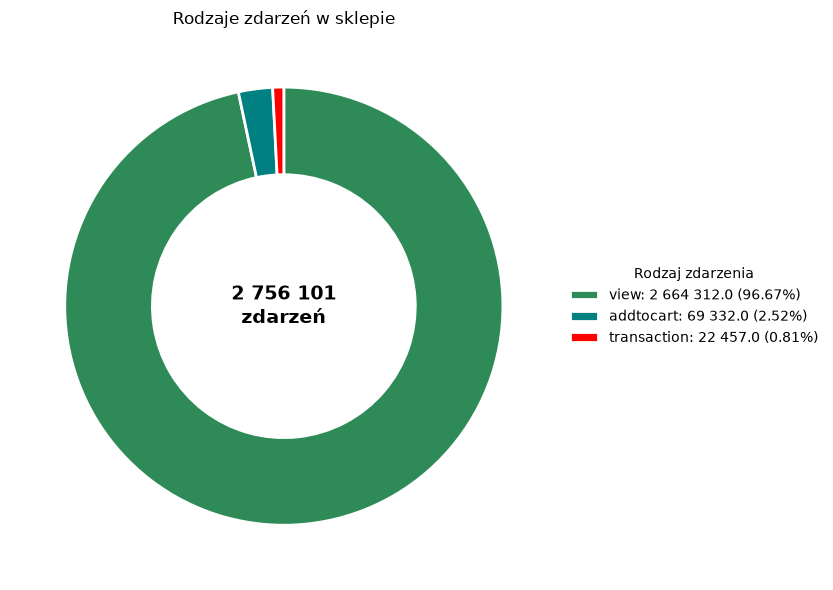

In [84]:
kolory = {'view': 'seagreen', 'addtocart': 'teal', 'transaction': 'red'}

fig, ax = plt.subplots(figsize=(9, 6))

wedges, _ = ax.pie(
    zdarzenia['liczba'],
    colors=[kolory[z] for z in zdarzenia.index],
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
)

# suma w środku
suma = f"{zdarzenia['liczba'].sum():,}".replace(',', ' ')
ax.text(0, 0, f'{suma}\nzdarzeń', ha='center', va='center',
        fontsize=14, fontweight='bold')

# legenda z liczbą i udziałem
etykiety = [f"{z}: {r.liczba:,} ({r.udzial_proc:.2f}%)".replace(',', ' ')
            for z, r in zdarzenia.iterrows()]
ax.legend(wedges, etykiety, title='Rodzaj zdarzenia',
          loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)

ax.set_title('Rodzaje zdarzeń w sklepie')
plt.tight_layout()
plt.show()

## 6. Aktywność w czasie

Rozważmy prosty wykres liniowy aktywności w sklepie. Zielonym kolorem oznaczymy ilość zdarzeń, niebieskim ilość użytkowników. Jeden użytkownik może powielać liczbę zdarzeń danego dnia, dlatego zdarzeń jest więcej.

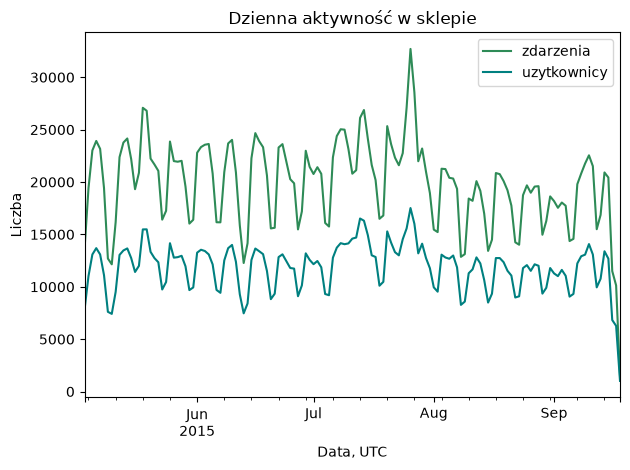

In [85]:
# Grupowanie po dniach
aktywnosc_dzienna = df.groupby('dzien').agg(
    zdarzenia=('event', 'size'),
    uzytkownicy=('visitorid', 'nunique')
)
wszystkie_dni = pd.date_range(df['dzien'].min(), df['dzien'].max(), freq='D') # Rozwazamy pelny zakres dni
aktywnosc_dzienna.index.name = 'dzien'

aktywnosc_dzienna.plot(color=['seagreen', 'teal'])
plt.title('Dzienna aktywność w sklepie')
plt.xlabel('Data, UTC')
plt.ylabel('Liczba')
plt.tight_layout()
plt.show()

Zobaczmy średnią aktywność w zależności od dnia tygodnia.

In [86]:
pelne_dni = aktywnosc_dzienna.iloc[1:-1]
najaktywniejszy_dzien = pelne_dni['zdarzenia'].idxmax()
print('Najaktywniejszy dzień:', najaktywniejszy_dzien.date())
print('Liczba zdarzeń:', pelne_dni.loc[najaktywniejszy_dzien, 'zdarzenia'])

Najaktywniejszy dzień: 2015-07-26
Liczba zdarzeń: 32703


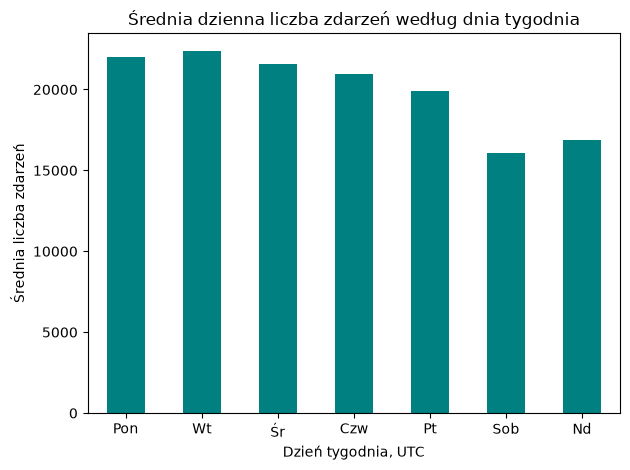

In [87]:
srednia_tygodniowa = pelne_dni.groupby(pelne_dni.index.day_of_week)['zdarzenia'].mean()
srednia_tygodniowa.index = ['Pon', 'Wt', 'Śr', 'Czw', 'Pt', 'Sob', 'Nd']
srednia_tygodniowa.plot(kind='bar', color='teal', rot=0)
plt.title('Średnia dzienna liczba zdarzeń według dnia tygodnia')
plt.xlabel('Dzień tygodnia, UTC')
plt.ylabel('Średnia liczba zdarzeń')
plt.tight_layout()
plt.show()

Największa dzienna aktywność przypada na **26.07.2015**, kiedy zarejestrowano **32 703 zdarzeń**. Średnio najwięcej zdarzeń przypada na wtorki, a najmniej na soboty.

Na końcu szeregu widać spadek, ale ostatni dzień obejmuje tylko około trzy godziny. Maj i wrzesień również obejmują niepełne miesiące. Same liczby zdarzeń nie wyjaśniają przyczyn zmian aktywności.

## 7. Ilu użytkowników kupuje?

In [88]:
zakupy = df[df['event'] == 'transaction'].copy()
liczba_uzytkownikow = df['visitorid'].nunique() # Daje unikalna liczbe uzytkownikow
liczba_kupujacych = zakupy['visitorid'].nunique() # Unikalna liczba kupujacych
liczba_transakcji = zakupy['transactionid'].nunique() # Unikalna liczba transakcji
kupujacy_procent = liczba_kupujacych / liczba_uzytkownikow * 100

print('Użytkownicy:', liczba_uzytkownikow)
print('Kupujący:', liczba_kupujacych)
print('Zdarzenia zakupu:', len(zakupy))
print('Unikalne transakcje:', liczba_transakcji)
print('Procent kupujących:', round(kupujacy_procent, 2), '%')

Użytkownicy: 1407580
Kupujący: 11719
Zdarzenia zakupu: 22457
Unikalne transakcje: 17672
Procent kupujących: 0.83 %


Kupujących jest bardzo mało w proporcji do zwykłych odwiedzających użytkowników. Zaledwie **0.83%**.

## 8. Sesje użytkowników

W danych nie ma gotowej informacji o sesjach, więc sam ją wyznaczam. Zakładam, że **nowa sesja zaczyna się, gdy użytkownik nie robił nic przez ponad 30 minut**. Jeśli przerwa wynosi dokładnie 30 minut, to nadal jest ta sama sesja. Sesja może trwać przez północ, bo nie dzielę jej według dni. Aczkolwiek, to tylko moje założenie, wybrałem je ponieważ jest to klasyczny czas stosowany w sklepach internetowych.

*"Domyślnie w Google Analytics sesja trwa 30 minut bezczynności – jeśli użytkownik nie wykona żadnej akcji przez pół godziny, sesja wygasa."* ~ Google AI.

In [89]:
# Sortowanie: zdarzenia każdego użytkownika po kolei, w kolejności czasu
df = df.sort_values(['visitorid', 'datetime', 'event_id']).reset_index(drop=True)
poprzedni_czas = df.groupby('visitorid')['datetime'].shift() # Czas poprzedniego zdarzenia tego samego użytkownika
przerwa = df['datetime'] - poprzedni_czas
nowa_sesja = poprzedni_czas.isna() | (przerwa > pd.Timedelta(minutes=30))
df['session_id'] = nowa_sesja.cumsum()

df['wyswietlenie'] = df['event'] == 'view' # True, jeśli zdarzenie to wyświetlenie
df['koszyk'] = df['event'] == 'addtocart' # True, jeśli zdarzenie to dodanie do koszyka
df['zakup'] = df['event'] == 'transaction' # True, jeśli zdarzenie to zakup

sesje = df.groupby('session_id').agg(
    visitorid=('visitorid', 'first'), # Kto to był (w sesji zawsze ta sama osoba)
    poczatek=('datetime', 'min'), # Pierwsze zdarzenie w sesji
    koniec=('datetime', 'max'), # Ostatnie zdarzenie w sesji
    liczba_zdarzen=('event', 'size'), # Ile zdarzeń miała sesja
    liczba_produktow=('itemid', 'nunique'), # Ile różnych produktów w sesji
    czy_zakup=('zakup', 'max') # True, jeśli w sesji był choć jeden zakup
)
sesje['czas_min'] = (sesje['koniec'] - sesje['poczatek']).dt.total_seconds() / 60 # Czas trwania sesji w minutach
sesje['dzien_startu'] = sesje['poczatek'].dt.floor('D') # Dzień, w którym sesja się zaczęła
konwersja_sesji = sesje['czy_zakup'].mean() * 100 # Odsetek sesji z zakupem w procentach

print('Sesje:', len(sesje)) # Liczba wszystkich sesji
print('Sesje zakupowe:', sesje['czy_zakup'].sum()) # Liczba sesji z zakupem
print('Konwersja sesji:', round(konwersja_sesji, 2), '%')
sesje.head()

Sesje: 1761675
Sesje zakupowe: 14297
Konwersja sesji: 0.81 %


,visitorid,poczatek,koniec,liczba_zdarzen,liczba_produktow,czy_zakup,czas_min,dzien_startu
session_id,,,,,,,,
1,0,2015-09-11 20:49:49.439+00:00,2015-09-11 20:55:17.175+00:00,3,3,False,5.462267,2015-09-11 00:00:00+00:00
2,1,2015-08-13 17:46:06.444+00:00,2015-08-13 17:46:06.444+00:00,1,1,False,0.000000,2015-08-13 00:00:00+00:00
3,2,2015-08-07 17:51:44.567+00:00,2015-08-07 18:20:57.845+00:00,8,4,False,29.221300,2015-08-07 00:00:00+00:00
4,3,2015-08-01 07:10:35.296+00:00,2015-08-01 07:10:35.296+00:00,1,1,False,0.000000,2015-08-01 00:00:00+00:00
5,4,2015-09-15 21:24:27.167+00:00,2015-09-15 21:24:27.167+00:00,1,1,False,0.000000,2015-09-15 00:00:00+00:00


Mamy piękną tabelę z informacjami dotyczącymi sesji użytkowników. Może pojawić się pytanie, co jeśli użytkownik miał tylko jedo zdarzenie - wówczas, `poczatek` i `koniec` to będzie ta sama data. Dla przykładu można zobaczyć sesje o id 2 w tabeli powyżej.

In [90]:
# Najdłuższa sesja
najdluzsza_id = sesje['czas_min'].idxmax()
najdluzsza = sesje.loc[najdluzsza_id]

print('Najdłuższa sesja (session_id =', najdluzsza_id, ')')
print('  Użytkownik:      ', najdluzsza['visitorid'])
print('  Początek:        ', najdluzsza['poczatek'])
print('  Koniec:          ', najdluzsza['koniec'])
print('  Czas trwania:    ', round(najdluzsza['czas_min'], 1), 'min',
      f"({najdluzsza['czas_min'] / 60:.1f} h)")
print('  Liczba zdarzeń:  ', najdluzsza['liczba_zdarzen'])
print('  Liczba produktów:', najdluzsza['liczba_produktow'])
print('  Czy zakup:       ', najdluzsza['czy_zakup'])

Najdłuższa sesja (session_id = 662589 )
  Użytkownik:       530033
  Początek:         2015-06-04 14:55:58.341000+00:00
  Koniec:           2015-06-05 03:04:22.589000+00:00
  Czas trwania:     728.4 min (12.1 h)
  Liczba zdarzeń:   310
  Liczba produktów: 206
  Czy zakup:        True


Jest szansa, że gościu był botem, albo to wyjątek z mojego założenia i sesja mogłaby trwać nieco dłużej.

In [91]:
# Najkrótsza sesja
zero_min = (sesje['czas_min'] == 0).sum()
print('\nSesje o czasie 0 min:', zero_min,
      f'({zero_min / len(sesje):.1%} wszystkich sesji)')


Sesje o czasie 0 min: 1379142 (78.3% wszystkich sesji)


In [92]:
# najkrótsza sesja złożona z co najmniej 2 zdarzeń
wielozdarzeniowe = sesje[sesje['liczba_zdarzen'] > 1]
najkrotsza_id = wielozdarzeniowe['czas_min'].idxmin()
najkrotsza = sesje.loc[najkrotsza_id]

print('\nNajkrótsza sesja z min. 2 zdarzeniami (session_id =', najkrotsza_id, ')')
print('  Użytkownik:      ', najkrotsza['visitorid'])
print('  Początek:        ', najkrotsza['poczatek'])
print('  Czas trwania:    ', round(najkrotsza['czas_min'] * 60, 1), 's')
print('  Liczba zdarzeń:  ', najkrotsza['liczba_zdarzen'])


Najkrótsza sesja z min. 2 zdarzeniami (session_id = 7128 )
  Użytkownik:       5703
  Początek:         2015-07-27 21:03:15.619000+00:00
  Czas trwania:     0.0 s
  Liczba zdarzeń:   2


To też jest mocny zawodnik, jestem ciekaw jakiego typu były te zdarzenia.

In [93]:
df[df['session_id'] == 7128]

,timestamp,visitorid,event,itemid,transactionid,datetime,dzien,event_id,session_id,wyswietlenie,koszyk,zakup
10876,1438030995619,5703,transaction,186214,3297,2015-07-27 21:03:15.619+00:00,2015-07-27 00:00:00+00:00,2649832,7128,False,False,True
10877,1438030995619,5703,transaction,295495,3297,2015-07-27 21:03:15.619+00:00,2015-07-27 00:00:00+00:00,2664129,7128,False,False,True


Po prostu jednym kliknięciem kupił dwa przedmioty - nie było tematu.

Sprawdzimy teraz co jeśli nasza przerwa będzie wynosiła kolejno **15**, **30** i **60** minut.

In [94]:
porownanie_progow = []
for minuty in [15, 30, 60]:
    start = poprzedni_czas.isna() | (przerwa > pd.Timedelta(minutes=minuty))
    numery = start.cumsum()
    liczba_sesji = int(start.sum())
    sesje_z_zakupem = numery[df['zakup']].nunique()
    porownanie_progow.append([minuty, liczba_sesji, sesje_z_zakupem,
                              sesje_z_zakupem / liczba_sesji * 100])

wrazliwosc = pd.DataFrame(porownanie_progow, columns=[
    'przerwa_min', 'sesje', 'sesje_zakupowe', 'zakupy_proc'
])
wrazliwosc.round(3)

,przerwa_min,sesje,sesje_zakupowe,zakupy_proc
0,15,1809161,15449,0.854
1,30,1761675,14297,0.812
2,60,1726714,13446,0.779


Za dużej różnicy nie ma. Przy większej przerwie liczba sesji łączy się, przez co unikalność transakcji jest mniejsza. Natomiast dalej pozostanę przy założeniu, że przerwa trwa max 30 min.

## 9. Kupujący a pozostali użytkownicy

Porównamy teraz kupujących oraz użytkowników, tylko przeglądających treści. Porównamy ilość zdarzeń oraz sesji. Użyjemy do tego mediany i średniej.

In [95]:
uzytkownicy = df.groupby('visitorid').agg(
    liczba_zdarzen=('event', 'size'), # Ile zdarzeń ma użytkownik
    liczba_produktow=('itemid', 'nunique'), # Ile różnych produktów oglądał
    aktywne_dni=('dzien', 'nunique'), # W ilu różnych dniach był aktywny
    koszyki=('koszyk', 'sum'), # Ile razy dodał do koszyka
    zdarzenia_zakupu=('zakup', 'sum') # Ile zdarzeń zakupu
)
uzytkownicy['liczba_sesji'] = sesje.groupby('visitorid').size() # Liczba sesji użytkownika (z tabeli sesje)
uzytkownicy['kupujacy'] = uzytkownicy['zdarzenia_zakupu'] > 0 # True, jeśli użytkownik kupił choć raz

porownanie_grup = uzytkownicy.groupby('kupujacy').agg(
    uzytkownicy=('liczba_zdarzen', 'size'), # Ilu użytkowników w grupie
    srednia_zdarzen=('liczba_zdarzen', 'mean'), # Średnia liczba zdarzeń
    mediana_zdarzen=('liczba_zdarzen', 'median'), # Mediana liczby zdarzeń
    srednia_produktow=('liczba_produktow', 'mean'), # Średnia liczba produktów
    mediana_produktow=('liczba_produktow', 'median'), # Mediana liczby produktów
    srednia_sesji=('liczba_sesji', 'mean'), # Średnia liczba sesji
    mediana_sesji=('liczba_sesji', 'median'), # Mediana liczby sesji
    srednia_aktywnych_dni=('aktywne_dni', 'mean'), # Średnia liczba aktywnych dni
    mediana_aktywnych_dni=('aktywne_dni', 'median') # Mediana liczby aktywnych dni
).rename(index={False: 'Niekupujący', True: 'Kupujący'})
display(porownanie_grup.round(2))

,uzytkownicy,srednia_zdarzen,mediana_zdarzen,srednia_produktow,mediana_produktow,srednia_sesji,mediana_sesji,srednia_aktywnych_dni,mediana_aktywnych_dni
kupujacy,,,,,,,,,
Niekupujący,1395861,1.81,1.0,1.46,1.0,1.23,1.0,1.16,1.0
Kupujący,11719,19.68,6.0,9.54,2.0,3.65,2.0,2.34,1.0


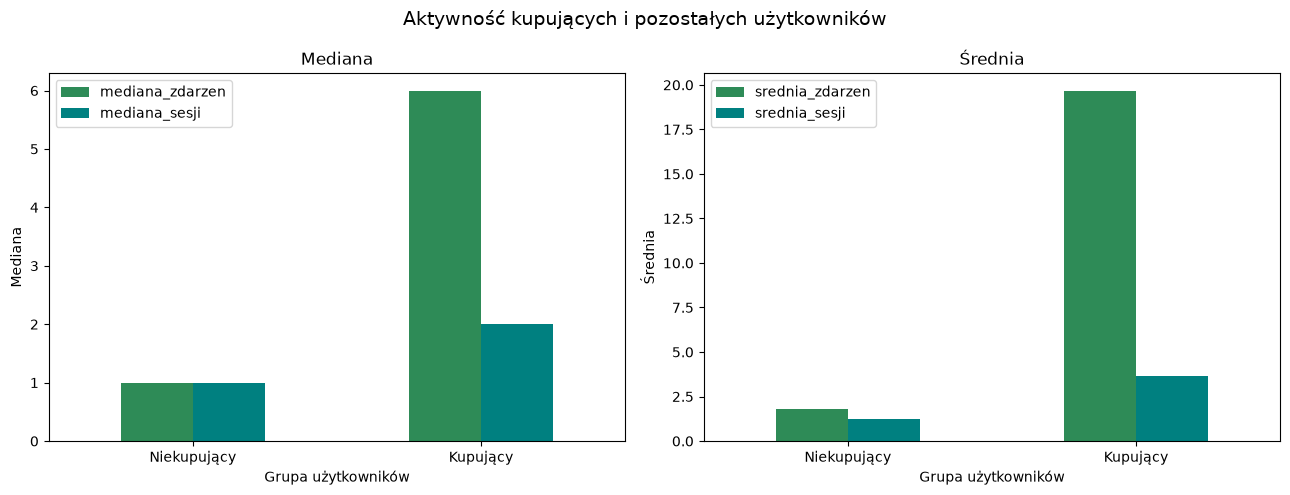

In [96]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Lewy wykres: mediany
porownanie_grup[['mediana_zdarzen', 'mediana_sesji']].plot(
    kind='bar', color=['seagreen', 'teal'], rot=0, ax=ax1
)
ax1.set_title('Mediana')
ax1.set_xlabel('Grupa użytkowników')
ax1.set_ylabel('Mediana')

# Prawy wykres: średnie
porownanie_grup[['srednia_zdarzen', 'srednia_sesji']].plot(
    kind='bar', color=['seagreen', 'teal'], rot=0, ax=ax2
)
ax2.set_title('Średnia')
ax2.set_xlabel('Grupa użytkowników')
ax2.set_ylabel('Średnia')

fig.suptitle('Aktywność kupujących i pozostałych użytkowników', fontsize=14) # Wspólny tytuł
plt.tight_layout()
plt.show()

Wiemy, że kupujący to bardziej aktywni klienci. Ta analiza daje nam zrozumienie zależności.

## 10. Ścieżka od wyświetlenia do zakupu

Sprawdzam ścieżkę **wyświetlenie → koszyk → zakup** dla tego samego produktu w tej samej sesji. Jednostką jest para `session_id` i `itemid`. Każda para może wejść na dany etap najwyżej raz.

In [97]:
klucze = ['session_id', 'itemid'] # Para = jeden produkt w jednej sesji
pary = df.groupby(klucze).agg(
    visitorid=('visitorid', 'first'), # Kto to był (w sesji zawsze ta sama osoba)
    wyswietlenia=('wyswietlenie', 'sum'), # Ile razy produkt wyświetlono w sesji
    koszyki=('koszyk', 'sum'), # Ile razy dodano go do koszyka
    zdarzenia_zakupu=('zakup', 'sum') # Ile zdarzeń zakupu dotyczyło produktu
)
pary['pierwszy_view'] = df[df['wyswietlenie']].groupby(klucze)['datetime'].min()
pary['pierwszy_koszyk'] = df[df['koszyk']].groupby(klucze)['datetime'].min()
pary['ma_view'] = pary['wyswietlenia'] > 0 # True, jeśli produkt był wyświetlony choć raz

koszyki_z_czasem = df.loc[df['koszyk'], klucze + ['datetime']].join(
    pary['pierwszy_view'], on=klucze
)
koszyki_po_view = koszyki_z_czasem[
    koszyki_z_czasem['datetime'] > koszyki_z_czasem['pierwszy_view']
    ]
pary['koszyk_po_view'] = koszyki_po_view.groupby(klucze)['datetime'].min()

Teraz do każdego zdarzenia zakupu dołączam wcześniejsze etapy. Szukam zakupu po pierwszym view i zakupu po koszyku, który sam nastąpił po view.

W porównaniach używam `>`, więc czasy muszą rosnąć ściśle. Przy identycznych czasach kolejność pozostaje nieustalona. Koszyk wcześniejszy niż view sam nie wystarczy, ale późniejszy koszyk może już utworzyć poprawną ścieżkę.

In [98]:
zakupy_z_etapami = df.loc[df['zakup'], klucze + ['datetime']].join( # Tylko zdarzenia zakupu (z czasem)
    pary[['pierwszy_view', 'pierwszy_koszyk', 'koszyk_po_view']], on=klucze # Dopisuje czasy wcześniejszych etapów dla tej samej pary sesja–produkt
)
zakupy_po_view = zakupy_z_etapami[
    zakupy_z_etapami['datetime'] > zakupy_z_etapami['pierwszy_view'] # Zostają zakupy późniejsze niż pierwsze view
    ]
zakupy_po_koszyku = zakupy_z_etapami[
    zakupy_z_etapami['datetime'] > zakupy_z_etapami['koszyk_po_view'] # Zostają zakupy późniejsze niż koszyk, który sam był po view
    ]
pary['zakup_po_view'] = zakupy_po_view.groupby(klucze)['datetime'].min() # Czas pierwszego zakupu po wyświetleniu
pary['zakup_pelna_sciezka'] = zakupy_po_koszyku.groupby(klucze)['datetime'].min() # Czas pierwszego zakupu po pełnej ścieżce view → koszyk → zakup
pary['view_koszyk'] = pary['koszyk_po_view'].notna() # True, jeśli był koszyk po wyświetleniu
pary['view_zakup'] = pary['zakup_po_view'].notna() # True, jeśli był zakup po wyświetleniu (z pominięciem koszyka lub bez)
pary['pelna_sciezka'] = pary['zakup_pelna_sciezka'].notna() # True, jeśli była pełna ścieżka view → koszyk → zakup

lejek = pd.DataFrame({'liczba_par': [ # Tabela lejka: ile par dotarło do każdego etapu
    pary['ma_view'].sum(), pary['view_koszyk'].sum(), pary['pelna_sciezka'].sum()
]}, index=['Wyświetlenie', 'Koszyk po wyświetleniu', 'Zakup po koszyku'])
lejek['przejscie_proc'] = lejek['liczba_par'] / lejek['liczba_par'].shift() * 100
display(lejek.round(2))

,liczba_par,przejscie_proc
Wyświetlenie,2330774,NaN
Koszyk po wyświetleniu,45114,1.94
Zakup po koszyku,14807,32.82


Widzimy, że jeśli użytkownik wrzucił produkt do koszyka było **32.82%** szans na jego zakup.

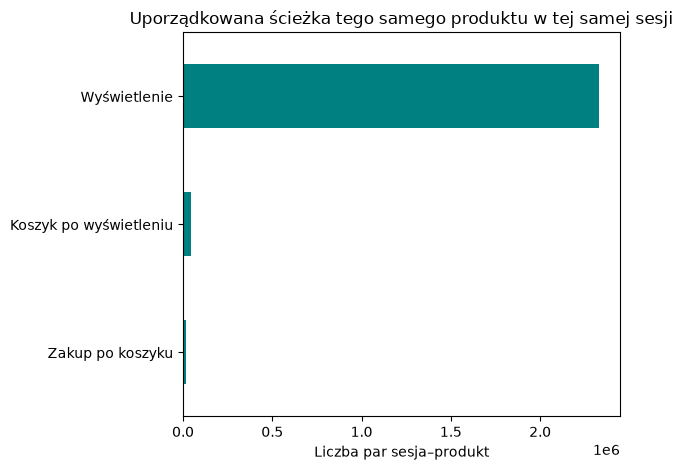

In [99]:
lejek['liczba_par'].iloc[::-1].plot(kind='barh', color='teal')
plt.title('Uporządkowana ścieżka tego samego produktu w tej samej sesji')
plt.xlabel('Liczba par sesja–produkt')
plt.tight_layout()
plt.show()

Solidnie, największy spadek występuje oczywiście po wyświetleniu - najczęściej produkty są **tylko** przeglądane.

Zobaczmy ile zakupów nie posiada wcześniej zdarzenia z view oraz ile jest transakcji bez dodania produktu do koszyka.

In [100]:
zakupy_z_etapami['visitorid'] = df.loc[zakupy_z_etapami.index, 'visitorid'] # Dopisuje użytkownika do każdego zakupu

klucz_u = ['visitorid', 'itemid'] # Para = użytkownik + produkt (niezależnie od sesji)
view_uz = df[df['wyswietlenie']].groupby(klucz_u)['datetime'].min().rename('view_uzytkownika') # Pierwsze view produktu w całej historii użytkownika
koszyk_uz = df[df['koszyk']].groupby(klucz_u)['datetime'].min().rename('koszyk_uzytkownika') # Pierwszy koszyk produktu w całej historii użytkownika

zakupy_hist = zakupy_z_etapami.join(view_uz, on=klucz_u).join(koszyk_uz, on=klucz_u) # Dopisuje historię użytkownika do każdego zakupu

# Zakupy bez view / koszyka w tej samej sesji
bez_view = ~(zakupy_hist['datetime'] > zakupy_hist['pierwszy_view'])
bez_koszyka = ~(zakupy_hist['datetime'] > zakupy_hist['pierwszy_koszyk'])

# Czy użytkownik miał view / koszyk tego produktu kiedykolwiek wcześniej
view_wczesniej = zakupy_hist['datetime'] > zakupy_hist['view_uzytkownika']
koszyk_wczesniej = zakupy_hist['datetime'] > zakupy_hist['koszyk_uzytkownika']

# Z zakupów bez view w sesji: ile miało view we wcześniejszej sesji
odzyskane_view = bez_view & view_wczesniej
brak_view_wcale = bez_view & ~view_wczesniej # Brak view w całej historii

# Z zakupów bez koszyka w sesji: ile miało koszyk we wcześniejszej sesji
odzyskane_koszyk = bez_koszyka & koszyk_wczesniej
brak_koszyka_wcale = bez_koszyka & ~koszyk_wczesniej # Brak koszyka w całej historii

print('Zakupy bez view w tej sesji:', bez_view.sum())
print('  w tym view w wcześniejszej sesji:', odzyskane_view.sum(),
      f'({odzyskane_view.sum() / bez_view.sum() * 100:.2f}%)')
print('  w tym brak view w ogóle:', brak_view_wcale.sum(),
      f'({brak_view_wcale.sum() / bez_view.sum() * 100:.2f}%)')

print('\nZakupy bez koszyka w tej sesji:', bez_koszyka.sum())
print('  w tym koszyk w wcześniejszej sesji:', odzyskane_koszyk.sum(),
      f'({odzyskane_koszyk.sum() / bez_koszyka.sum() * 100:.2f}%)')
print('  w tym brak koszyka w ogóle:', brak_koszyka_wcale.sum(),
      f'({brak_koszyka_wcale.sum() / bez_koszyka.sum() * 100:.2f}%)')

print('\nZakupy bez view w całej historii:', brak_view_wcale.sum(),
      f'czyli {brak_view_wcale.mean() * 100:.2f}% wszystkich zakupów')
print('Zakupy bez koszyka w całej historii:', brak_koszyka_wcale.sum(),
      f'czyli {brak_koszyka_wcale.mean() * 100:.2f}% wszystkich zakupów')

Zakupy bez view w tej sesji: 4742
  w tym view w wcześniejszej sesji: 2109 (44.47%)
  w tym brak view w ogóle: 2633 (55.53%)

Zakupy bez koszyka w tej sesji: 4472
  w tym koszyk w wcześniejszej sesji: 2020 (45.17%)
  w tym brak koszyka w ogóle: 2452 (54.83%)

Zakupy bez view w całej historii: 2633 czyli 11.72% wszystkich zakupów
Zakupy bez koszyka w całej historii: 2452 czyli 10.92% wszystkich zakupów


**Większość zakupów (ok. 79%) ma view w tej samej sesji.** Typowy klient wchodzi, ogląda produkt i kupuje podczas jednej wizyty. **Ok. 9% zakupów to powroty.** Klient obejrzał produkt (albo dodał go do koszyka) wcześniej, wyszedł, a kupił dopiero w kolejnej sesji. Lejek liczony tylko w obrębie sesji tych zakupów nie widzi, więc **zaniża** liczbę ścieżek zakończonych zakupem.

**Ok. 11% zakupów nie ma w danych żadnego wcześniejszego view.** Może to oznaczać, że:
 - klient oglądał produkt przed początkiem zbioru danych,
 - oglądał go na innym urządzeniu lub w innej przeglądarce (dla zbioru to inny `visitorid`),
 - wszedł bezpośrednio z linku (mail, reklama),
 - w danych brakuje części zdarzeń.

## 11. Ile czasu upływa od view do zakupu?

Bierzemy pierwsze view i pierwszy zakup dla danej pary. Różnica będzie przekonwertowana na minuty. Pominiemy proces dodawania do koszyka. Nie jest istotne czy view nastąpiło w tej samej sesji co transakcja, czy wcześniejszej.

In [101]:
klucz_u = ['visitorid', 'itemid'] # Para = użytkownik + produkt, niezależnie od sesji

zakupy_po_view_uz = zakupy_hist[zakupy_hist['datetime'] > zakupy_hist['view_uzytkownika']] # Zakupy późniejsze niż pierwsze view tego produktu u użytkownika

pierwszy_zakup = (
    zakupy_po_view_uz.sort_values('datetime') # Najwcześniejszy zakup na górze
    .groupby(klucz_u)[['datetime', 'session_id']].first() # Pierwszy zakup po view i sesja, w której padł
    .rename(columns={'datetime': 'zakup_po_view', 'session_id': 'sesja_zakupu'})
)

pary_uz = view_uz.to_frame().join(pierwszy_zakup, how='inner') # Zostają tylko pary, które miały view i późniejszy zakup
pary_uz['sesja_view'] = df[df['wyswietlenie']].groupby(klucz_u)['session_id'].first() # Sesja pierwszego view
pary_uz['ta_sama_sesja'] = pary_uz['sesja_view'] == pary_uz['sesja_zakupu'] # True = zakup w sesji pierwszego view, False = powrót w kolejnej sesji

pary_uz['czas_do_zakupu_min'] = (
    pary_uz['zakup_po_view'] - pary_uz['view_uzytkownika'] # Ile czasu minęło od pierwszego view do pierwszego zakupu po nim
).dt.total_seconds() / 60 # Zamiana na minuty
pary_uz['czas_do_zakupu_h'] = pary_uz['czas_do_zakupu_min'] / 60 # To samo w godzinach
pary_uz['czas_do_zakupu_dni'] = pary_uz['czas_do_zakupu_h'] / 24 # I w dniach

print('Liczba par z dopasowaniem:', len(pary_uz))
print('W tej samej sesji:', pary_uz['ta_sama_sesja'].sum(),
      f"({pary_uz['ta_sama_sesja'].mean() * 100:.2f}%)") # Udział zakupów bez powrotu
print('Po powrocie (inna sesja):', (~pary_uz['ta_sama_sesja']).sum(),
      f"({(~pary_uz['ta_sama_sesja']).mean() * 100:.2f}%)") # Udział zakupów po powrocie

Liczba par z dopasowaniem: 18778
W tej samej sesji: 14293 (76.12%)
Po powrocie (inna sesja): 4485 (23.88%)


In [102]:
print('Czas do zakupu w minutach, osobno dla grup:')
display(pary_uz.groupby('ta_sama_sesja')['czas_do_zakupu_min'] # Porównanie szybkich zakupów i powrotów
        .describe(percentiles=[0.25, 0.5, 0.75]).round(2)
        .rename(index={True: 'Ta sama sesja', False: 'Powrót w innej sesji'}))

Czas do zakupu w minutach, osobno dla grup:


,count,mean,std,min,25%,50%,75%,max
ta_sama_sesja,,,,,,,,
Powrót w innej sesji,4485.0,6134.80,15084.93,30.55,124.47,936.26,4478.14,188609.95
Ta sama sesja,14293.0,10.92,14.01,0.18,3.25,5.98,13.11,257.09


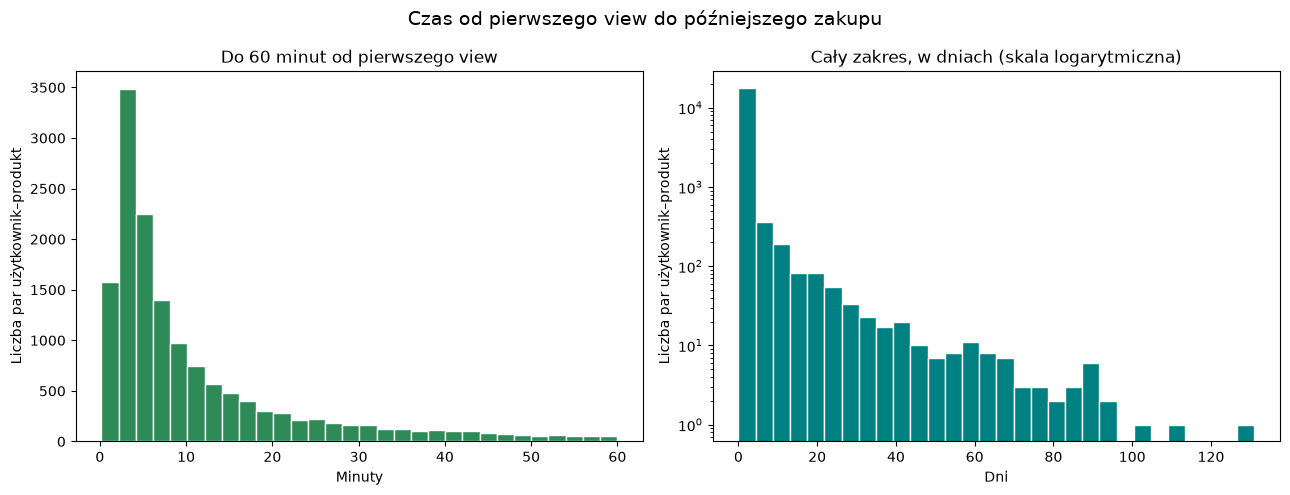

In [103]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Lewy: do 60 minut
pary_uz.loc[pary_uz['czas_do_zakupu_min'] <= 60, 'czas_do_zakupu_min'].plot(
    kind='hist', bins=30, color='seagreen', edgecolor='white', ax=ax1
)
ax1.set_title('Do 60 minut od pierwszego view')
ax1.set_xlabel('Minuty')
ax1.set_ylabel('Liczba par użytkownik–produkt')

# Prawy: cały zakres w dniach, oś Y logarytmiczna (ogon jest bardzo długi)
pary_uz['czas_do_zakupu_dni'].plot(
    kind='hist', bins=30, color='teal', edgecolor='white', ax=ax2, log=True
)
ax2.set_title('Cały zakres, w dniach (skala logarytmiczna)')
ax2.set_xlabel('Dni')
ax2.set_ylabel('Liczba par użytkownik–produkt')

fig.suptitle('Czas od pierwszego view do późniejszego zakupu', fontsize=14)
plt.tight_layout()
plt.show()

Widzimy, że zakup zazwyczaj zdarza się w pierwszym dniu, chociaż mamy wyjątki i widzimy, że zakupy potrafiły przeciągać się od pierwszego view danego produktu do **20**, **40**, **60**, a nawet **80** dni. Mamy również rekordzistę, który po pierwszym zobaczeniu produktu czekał ponad **120** dni!

## 12. Produkty często oglądane i rzadko kupowane

Tworzymy ranking produktów w zależności od oglądania oraz kupowania. Jesli użytkownik obejrzał produkt raz, to jego ponowne wyświetlenie produktu nie zwiększy liczby oglądań. Robimy przelicznik produktu na osobę.

Do rankingu ustalę limit min 100 wyświetleń produktu.

In [104]:
produkty = df.groupby('itemid').agg(
    wyswietlenia=('wyswietlenie', 'sum'), # Ile razy produkt wyświetlono (wszystkie zdarzenia view)
    zdarzenia_zakupu=('zakup', 'sum') # Ile zdarzeń zakupu dotyczyło produktu
)
produkty['ogladajacy'] = df[df['wyswietlenie']].groupby('itemid')['visitorid'].nunique() # Ilu unikalnych użytkowników oglądało produkt
produkty['kupujacy_po_view'] = pary[pary['view_zakup']].groupby('itemid')['visitorid'].nunique() # Ilu unikalnych użytkowników kupiło produkt po jego obejrzeniu w tej samej sesji
produkty[['ogladajacy', 'kupujacy_po_view']] = (
    produkty[['ogladajacy', 'kupujacy_po_view']].fillna(0).astype('int64')
)
produkty['zakup_proc'] = (
        produkty['kupujacy_po_view'] / produkty['ogladajacy'].replace(0, float('nan')) * 100 # Jaki procent oglądających kupił produkt
)
minimum_ogladajacych = 100
niska_konwersja = produkty[produkty['ogladajacy'] >= minimum_ogladajacych].sort_values( # Zostają tylko produkty z co najmniej 100 oglądającymi
    ['zakup_proc', 'ogladajacy'], ascending=[True, False] # Najniższy zakup_proc na górze, a przy remisie ten z większą liczbą oglądających
)
niska_konwersja.head(10).round(2)

,wyswietlenia,zdarzenia_zakupu,ogladajacy,kupujacy_po_view,zakup_proc
itemid,,,,,
187946,3410,0,2911,0,0.0
5411,2325,0,2078,0,0.0
370653,1854,0,1577,0,0.0
96924,1633,0,1359,0,0.0
298009,1642,0,1342,0,0.0
335975,1428,0,1154,0,0.0
151444,1230,0,1103,0,0.0
434782,1069,0,938,0,0.0
142466,1135,0,936,0,0.0


Produkt **187946** obejrzało **2 911 różnych użytkowników**, a w logu nie ma jego zakupu. To przykład dużego zainteresowania bez zarejestrowanej transakcji.

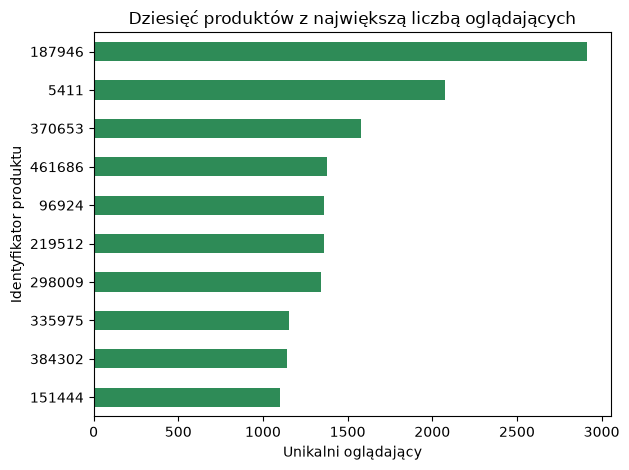

In [105]:
produkty['ogladajacy'].nlargest(10).sort_values().plot(kind='barh', color='seagreen')
plt.title('Dziesięć produktów z największą liczbą oglądających')
plt.xlabel('Unikalni oglądający')
plt.ylabel('Identyfikator produktu')
plt.tight_layout()
plt.show()

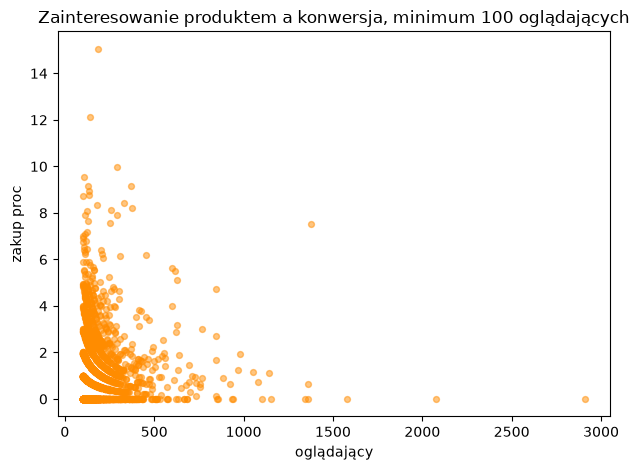

In [106]:
niska_konwersja.plot(kind='scatter', x='ogladajacy', y='zakup_proc',
                     color='darkorange', alpha=0.5, s=18)
plt.title('Zainteresowanie produktem a konwersja, minimum 100 oglądających')
plt.xlabel('oglądający')
plt.ylabel('zakup proc')
plt.tight_layout()
plt.show()

## 13. Prosta segmentacja użytkowników

Podzielmy naszych użytkowników na klasy - zobaczmy jak sobie radzą poszczególne grupy. Proponuje:
  - **Niekupujący z jednej sesji oraz bez koszyka**,
  - **Niekupujący, którzy wracają oraz bez koszyka**,
  - **Niekupujący z koszykiem**,
  - **Kupujący podczas jednej sesji**,
  - **Kupujący, który ma wiele sesji**.

In [107]:
uzytkownicy['segment'] = 'Niekupujący, jedna sesja bez koszyka' # Wartość domyślna dla wszystkich
uzytkownicy.loc[uzytkownicy['liczba_sesji'] > 1, 'segment'] = 'Niekupujący, powracający bez koszyka' # Sesja > 1
uzytkownicy.loc[uzytkownicy['koszyki'] > 0, 'segment'] = 'Niekupujący z koszykiem' # Dodał coś do koszyka
uzytkownicy.loc[uzytkownicy['kupujacy'] & (uzytkownicy['liczba_sesji'] == 1), 'segment'] = 'Kupujący, jedna sesja' # Kupił podczas jednej wizyty
uzytkownicy.loc[uzytkownicy['kupujacy'] & (uzytkownicy['liczba_sesji'] > 1), 'segment'] = 'Kupujący, wiele sesji' # Kupił i odwiedził sklep więcej niż raz

segmenty = uzytkownicy.groupby('segment').agg(
    osoby=('liczba_zdarzen', 'size'), # Ilu użytkowników w segmencie
    mediana_zdarzen=('liczba_zdarzen', 'median'), # Typowa liczba zdarzeń
    mediana_sesji=('liczba_sesji', 'median'), # Typowa liczba sesji
    mediana_produktow=('liczba_produktow', 'median'), # Typowa liczba różnych produktów
    mediana_aktywnych_dni=('aktywne_dni', 'median') # Typowa liczba aktywnych dni
).sort_values('osoby', ascending=False) # Największy segment na górze tabeli
segmenty['udzial_proc'] = segmenty['osoby'] / len(uzytkownicy) * 100 # Jaki procent wszystkich użytkowników stanowi segment
display(segmenty.round(2))

,osoby,mediana_zdarzen,mediana_sesji,mediana_produktow,mediana_aktywnych_dni,udzial_proc
segment,,,,,,
"Niekupujący, jedna sesja bez koszyka",1203032,1.0,1.0,1.0,1.0,85.47
"Niekupujący, powracający bez koszyka",165683,3.0,2.0,2.0,2.0,11.77
Niekupujący z koszykiem,27146,4.0,1.0,2.0,1.0,1.93
"Kupujący, wiele sesji",6400,10.0,3.0,4.0,2.0,0.45
"Kupujący, jedna sesja",5319,4.0,1.0,1.0,1.0,0.38


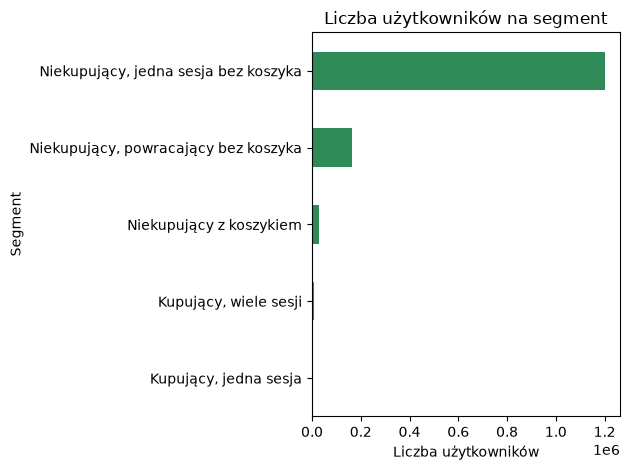

In [108]:
segmenty['osoby'].sort_values().plot(kind='barh', color='seagreen')
plt.title('Liczba użytkowników na segment')
plt.xlabel('Liczba użytkowników')
plt.ylabel('Segment')
plt.tight_layout()
plt.show()

Największa grupa to niekupujący z jedną sesją i bez koszyka. Stanowią aż **85.47%** całego zbioru.

## 14. Podsumowanie I etapu

Źródło danych [Retailrocket na Kaggle](https://www.kaggle.com/datasets/retailrocket/ecommerce-dataset).

### *📋 Co zostało wykonane i najważniejsze wyniki*

#### *🔍 1. Kontrola jakości danych*

| Sprawdzenie | Wynik |
|---|---|
| Braki danych (`null`) | **0** w kolumnach `timestamp`, `visitorid`, `event` i `itemid`. W `transactionid` są **2 733 644** puste wartości, wszystkie przy wyświetleniach lub dodaniach do koszyka. |
| Duplikaty | **0,0167%** wierszy, czyli **460** nadmiarowych powtórzeń. |
| Spójność `transactionid` | Występuje **wyłącznie** przy zdarzeniu `transaction`. Każde zdarzenie zakupu ma identyfikator transakcji. |

> ✅ **Wniosek:** dane nie wymagały dużego czyszczenia.

---

#### *📅 2. Zakres obserwacji*

- **Początek:** 3 maja 2015, godz. 03:00:04 UTC.
- **Koniec:** 18 września 2015, godz. 02:59:47 UTC.
- **Łącznie:** 139 dni kalendarzowych, licząc obie daty.
- Pierwszy i ostatni dzień są **niepełne**. Pominąłem je przy porównywaniu aktywności według dnia tygodnia.

---

#### *🛒 3. Struktura zdarzeń*

| Zdarzenie | Znaczenie | Udział |
|---|---|---|
| `view` | wyświetlenie produktu | **96,67%** (2 664 312 zdarzeń) |
| `addtocart` | dodanie do koszyka | **2,52%** (69 332 zdarzenia) |
| `transaction` | zakup produktu | **0,81%** (22 457 zdarzeń) |

> 💡 **Wniosek:** zdecydowana większość ruchu to oglądanie produktów.

---

#### *📈 4. Aktywność w czasie*

- Na wykresie dziennym porównałem **liczbę zdarzeń** i **liczbę unikalnych użytkowników**.
- Widać **wzorzec tygodniowy**. Średnio najwięcej zdarzeń przypadało na **wtorki**, a najmniej na **soboty**.
- **Pik pod koniec lipca:** 26 lipca 2015 zarejestrowano **32 703 zdarzenia**.
- Ostatni dzień wygląda na gwałtowny spadek, ale zapis obejmuje tylko **około trzech godzin**.

---

#### *👥 5. Ilu użytkowników kupuje?*

| Wskaźnik | Wartość |
|---|---:|
| Unikalni użytkownicy | 1 407 580 |
| Kupujący | 11 719 |
| **Procent kupujących** | **0,83%** |
| Zdarzenia zakupu | 22 457 |
| Unikalne transakcje | 17 672 |

> 💡 **Wniosek:** zakup zarejestrowano u **11 719 spośród 1 407 580 użytkowników**.

---

#### *⏱️ 6. Sesje*

- Nowa sesja zaczyna się po przerwie **dłuższej niż 30 minut** między kolejnymi zdarzeniami tego samego użytkownika. To moje założenie analityczne.
- **Liczba sesji:** 1 761 675, w tym **14 297** z co najmniej jednym zakupem.
- **Konwersja sesji:** 14 297 sesji zakupowych / 1 761 675 wszystkich sesji = **0,81%**.

---

#### *👤 7. Czym różnią się kupujący od pozostałych?*

| Wskaźnik na użytkownika | Kupujący — średnia | Kupujący — mediana | Niekupujący — średnia | Niekupujący — mediana |
|---|---:|---:|---:|---:|
| Liczba zdarzeń | 19,68 | **6** | 1,81 | **1** |
| Liczba sesji | 3,65 | **2** | 1,23 | **1** |
| Liczba różnych produktów, których dotyczyły zdarzenia | 9,54 | **2** | 1,46 | **1** |
| Liczba aktywnych dni | 2,34 | **1** | 1,16 | **1** |

> 💡 **Wniosek:** kupujący częściej wracali do sklepu i wykonywali więcej działań. Szczególnie dobrze widać to przy liczbie zdarzeń. Wśród kupujących średnia wynosiła prawie **20**, ale mediana tylko **6**.

---

#### *🔄 8. Lejek zakupowy*

Sprawdziłem ścieżkę **wyświetlenie → koszyk → zakup** dla tego samego produktu w tej samej sesji.

| Etap | Liczba par | Przejście |
|---|---:|---|
| Wyświetlenie | 2 330 774 | Punkt początkowy |
| Koszyk po wyświetleniu | 45 114 | **1,94%** par z wyświetleniem |
| Zakup po takim koszyku | 14 807 | **32,82%** par z koszykiem po wyświetleniu |

> 💡 **Wniosek:** największy spadek widać między **wyświetleniem a koszykiem**. Tylko około 2 na 100 par przeszły ten etap.

**Co widać po uwzględnieniu wcześniejszych sesji?**

| Gdzie było wcześniejsze zdarzenie? | Wyświetlenie produktu | Dodanie do koszyka |
|---|---:|---:|
| W sesji zakupu | 17 715 (78,88%) | 17 985 (80,09%) |
| Tylko we wcześniejszej sesji | 2 109 (9,39%) | 2 020 (8,99%) |
| Brak wcześniejszego zdarzenia w całym zbiorze | 2 633 (11,72%) | 2 452 (10,92%) |

---

#### *⏳ 9. Ile czasu upływa od obejrzenia produktu do zakupu?*

| Kiedy użytkownik kupił produkt? | Liczba par | Udział dopasowanych par | Mediana czasu od pierwszego wyświetlenia |
|---|---:|---:|---:|
| W sesji pierwszego wyświetlenia | 14 293 | 76,12% | **5,98 min** |
| Po powrocie w innej sesji | 4 485 | 23,88% | **936,26 min**, czyli ok. **15 godz. 36 min** |

> 💡 **Wniosek:** dla około trzech czwartych dopasowanych par zakup nastąpił już podczas pierwszej sesji, w której użytkownik oglądał produkt. Mediana wyniosła wtedy **6 minut**. Przy powrotach połowa zakupów nastąpiła w ciągu **15,5 godziny** od pierwszego wyświetlenia, a najdłuższy odstęp wyniósł **131 dni**.

---

#### *📦 10. Które produkty są często oglądane, ale rzadko kupowane?*

| Produkt (`itemid`) | Wyświetlenia | Unikalni oglądający | Zdarzenia zakupu |
|---|---:|---:|---:|
| `187946` | 3 410 | **2 911** | **0** |
| `5411` | 2 325 | **2 078** | **0** |
| `370653` | 1 854 | **1 577** | **0** |

> 💡 **Wniosek:** produkt `187946` obejrzało prawie 3 tys. użytkowników, bez odnotowania jego zakupu.

---

#### *🧩 11. Segmenty użytkowników*

| Segment | Liczba użytkowników | Udział |
|---|---:|---:|
| Niekupujący, jedna sesja bez koszyka | **1 203 032** | **85,47%** |
| Niekupujący, powracający bez koszyka | 165 683 | 11,77% |
| Niekupujący z koszykiem | 27 146 | 1,93% |
| Kupujący, wiele sesji | 6 400 | 0,45% |
| Kupujący, jedna sesja | 5 319 | 0,38% |

## 15. Zapis tabel do dalszej pracy

Zapisuję wyniki do folderu `dane_powerbi_etap1`. W następnej części projektu użyję ich do zbudowania relacji i interaktywnego raportu.

In [109]:
folder_wynikow = Path('dane_powerbi_etap1')
folder_wynikow.mkdir(exist_ok=True)

# Jeden wiersz w tabeli pary oznacza jeden produkt w jednej sesji.
pary['dzien_startu'] = pary.index.get_level_values('session_id').map(sesje['dzien_startu'])

# Czas od pierwszego wyświetlenia do pierwszego późniejszego zakupu w tej sesji.
# Jeśli takiego zakupu nie było, pole w CSV pozostanie puste.
pary['czas_do_zakupu_min'] = (
    pary['zakup_po_view'] - pary['pierwszy_view']
).dt.total_seconds() / 60

kolumny_par = [
    'visitorid', 'dzien_startu', 'wyswietlenia', 'koszyki', 'zdarzenia_zakupu',
    'ma_view', 'view_koszyk', 'view_zakup', 'pelna_sciezka', 'czas_do_zakupu_min'
]

kolumny_zdarzen = [
    'event_id', 'timestamp', 'dzien', 'visitorid',
    'itemid', 'event', 'transactionid', 'session_id'
]

# W pary_uz jeden wiersz oznacza użytkownika i produkt.
# Pierwsze wyświetlenie i późniejszy zakup mogą pochodzić z różnych sesji.
kolumny_czasu = [
    'view_uzytkownika', 'zakup_po_view', 'sesja_view', 'sesja_zakupu',
    'ta_sama_sesja', 'czas_do_zakupu_min', 'czas_do_zakupu_h', 'czas_do_zakupu_dni'
]

# reset_index() przenosi identyfikatory z indeksu do zwykłych kolumn w CSV.
tabele = {
    'zdarzenia.csv': df[kolumny_zdarzen],
    'sesje.csv': sesje.reset_index(),
    'sciezki.csv': pary[kolumny_par].reset_index(),
    'czas_do_zakupu.csv': pary_uz[kolumny_czasu].reset_index(),
    'uzytkownicy.csv': uzytkownicy.reset_index(),
    'produkty.csv': pd.DataFrame({'itemid': produkty.index}),
    'kalendarz.csv': pd.DataFrame({'dzien': wszystkie_dni})
}

for nazwa_pliku, tabela in tabele.items():
    tabela.to_csv(folder_wynikow / nazwa_pliku, index=False, encoding='utf-8-sig')
    print(f'{nazwa_pliku} — {len(tabela):,} wierszy'.replace(',', ' '))

zdarzenia.csv — 2 756 101 wierszy
sesje.csv — 1 761 675 wierszy
sciezki.csv — 2 347 853 wierszy
czas_do_zakupu.csv — 18 778 wierszy
uzytkownicy.csv — 1 407 580 wierszy
produkty.csv — 235 061 wierszy
kalendarz.csv — 139 wierszy


### Pliki CSV do Power BI

| Plik | Co zawiera? |
|---|---|
| `zdarzenia.csv` | Każde wyświetlenie produktu, dodanie do koszyka i zakup. |
| `sesje.csv` | Wizyty użytkowników w sklepie, ich czas trwania i informację, czy podczas wizyty był zakup. |
| `sciezki.csv` | Etapy, przez które przeszedł użytkownik dla danego produktu podczas jednej wizyty: wyświetlenie, koszyk i zakup. |
| `czas_do_zakupu.csv` | Czas od pierwszego wyświetlenia produktu do zakupu oraz informację, czy użytkownik kupił go podczas tej samej wizyty, czy po powrocie. |
| `uzytkownicy.csv` | Podsumowanie aktywności każdego użytkownika i jego segment. |
| `produkty.csv` | Listę identyfikatorów produktów. |
| `kalendarz.csv` | Listę dni objętych analizą. |